# Etapa 2: análise exploratória

Entrada: `data/processed/emprestimos.csv`, gerado pela etapa 1.

A etapa responde a quatro perguntas antes de qualquer modelo:

1. As classes estão equilibradas?
2. Como os atributos se distribuem, e os dados parecem reais?
3. Quais atributos dizem a mesma coisa?
4. Quais atributos se relacionam com a aprovação?

Gráficos e tabelas usam os nomes em português de `config.NOMES`; o código usa os nomes originais do Kaggle.

## 0. Configuração

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config

base = pd.read_csv(config.PROCESSED_CSV)
NUMERICOS = [c for c in config.FEATURES if c not in ("education", "self_employed")]
print(base.shape)
pd.DataFrame({"nome original": list(config.NOMES), "nome usado": list(config.NOMES.values())})

(4269, 13)


,nome original,nome usado
0,no_of_dependents,dependentes
1,education,graduado
2,self_employed,autônomo
3,income_annum,renda anual
4,loan_amount,valor do empréstimo
5,loan_term,prazo (anos)
6,cibil_score,score de crédito
7,residential_assets_value,patrimônio residencial
8,commercial_assets_value,patrimônio comercial
9,luxury_assets_value,bens de luxo


## 1. Balanço das classes

In [2]:
situacao = base[config.TARGET].map({1: "aprovado", 0: "rejeitado"}).rename("situação")
contagem = situacao.value_counts()
pd.DataFrame({"empréstimos": contagem, "%": (100 * contagem / len(base)).round(1)})

,empréstimos,%
situação,,
aprovado,2656,62.2
rejeitado,1613,37.8


62,2% dos pedidos são aprovados. Um modelo que responde sempre "aprovado" acerta 62,2%: esse é o piso. As classes não estão muito desbalanceadas, mas a divisão treino-teste precisa ser estratificada para manter essa proporção nos dois lados.

## 2. Distribuições

Um histograma por atributo numérico (os 9 que não são 0/1; graduado e autônomo têm cerca de 50% cada). A altura de cada barra é o número de pedidos naquela faixa de valores. Valores em dinheiro aparecem em milhões.

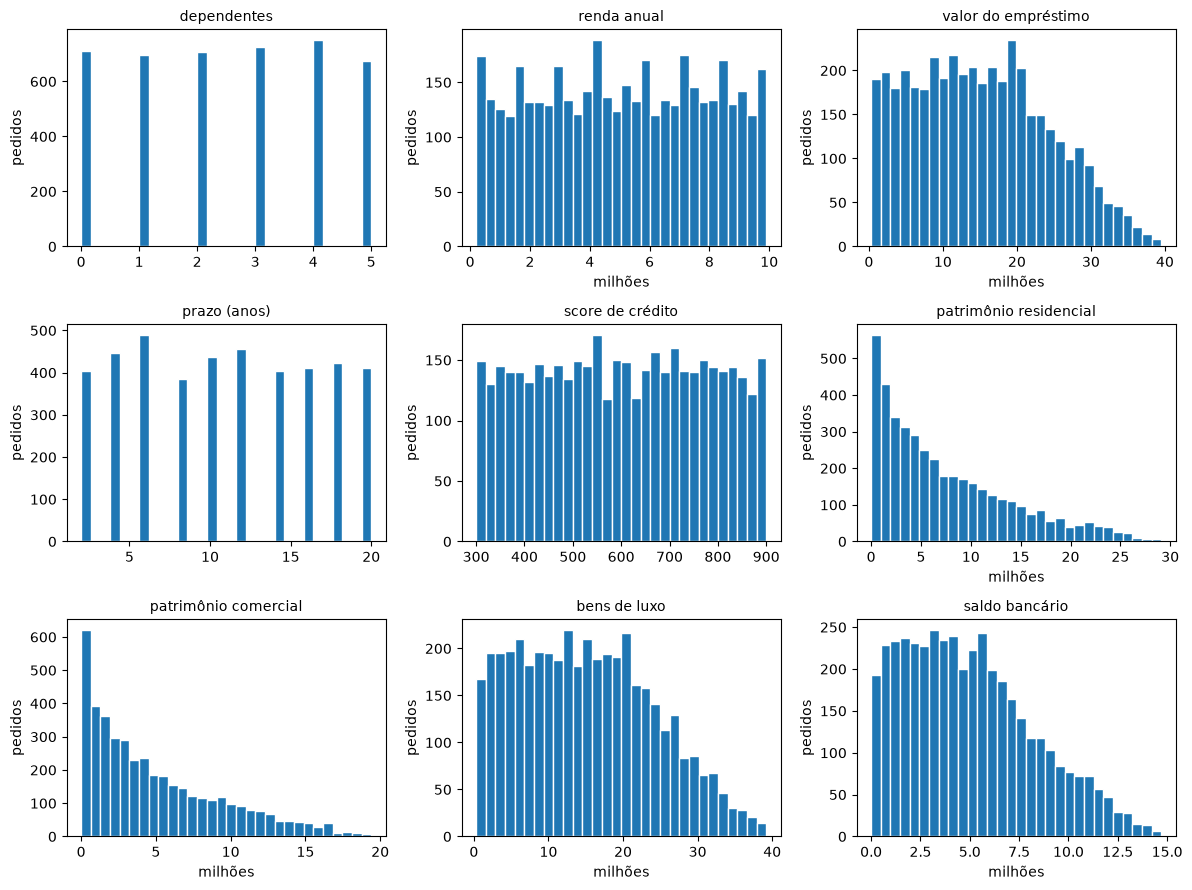

In [3]:
fig, eixos = plt.subplots(3, 3, figsize=(12, 9))
for ax, coluna in zip(eixos.flat, NUMERICOS):
    valores = base[coluna] / 1e6 if coluna in config.DINHEIRO else base[coluna]
    ax.hist(valores, bins=30, color="tab:blue", edgecolor="white")
    ax.set_title(config.NOMES[coluna], fontsize=10)
    ax.set_xlabel("milhões" if coluna in config.DINHEIRO else "")
    ax.set_ylabel("pedidos")
plt.tight_layout()
plt.show()

Vários atributos têm histograma "achatado": cada faixa de valores tem mais ou menos o mesmo número de pedidos, como num dado. É o caso do score de crédito, da renda anual, do prazo e do número de dependentes. Dados reais de crédito costumam se concentrar em alguma região (formato de sino, ou muitos clientes de renda baixa e poucos de renda alta).

Numa distribuição uniforme, o desvio padrão é (máximo − mínimo) / √12 e os quartis ficam igualmente espaçados entre o mínimo e o máximo. Os quartis dividem os pedidos, ordenados pelo valor, em quatro grupos do mesmo tamanho: 25% ficam abaixo do Q1, 50% abaixo da mediana e 75% abaixo do Q3. A tabela compara os valores reais com os de uma distribuição uniforme.

In [4]:
def comparar_com_uniforme(coluna):
    s = base[coluna]
    minimo, maximo = s.min(), s.max()
    return pd.Series({
        "desvio (real)": s.std(),
        "desvio (uniforme)": (maximo - minimo) / 12 ** 0.5,
        "Q1 (real)": s.quantile(0.25),
        "Q1 (uniforme)": minimo + 0.25 * (maximo - minimo),
        "mediana (real)": s.median(),
        "mediana (uniforme)": (minimo + maximo) / 2,
        "Q3 (real)": s.quantile(0.75),
        "Q3 (uniforme)": minimo + 0.75 * (maximo - minimo),
    })

pd.DataFrame({config.NOMES[c]: comparar_com_uniforme(c) for c in ["cibil_score", "income_annum"]}).round(0)

,score de crédito,renda anual
desvio (real),172.0,2806840.0
desvio (uniforme),173.0,2800149.0
Q1 (real),453.0,2700000.0
Q1 (uniforme),450.0,2625000.0
mediana (real),600.0,5100000.0
mediana (uniforme),600.0,5050000.0
Q3 (real),748.0,7500000.0
Q3 (uniforme),750.0,7475000.0


O score e a renda batem quase exatamente com uma distribuição uniforme: desvio, quartis e mediana. Somado à divisão quase exata de 50/50 em graduado e autônomo, e à falta de qualquer informação de origem na página do Kaggle, isso indica que a base provavelmente foi gerada por um programa. As conclusões valem para esta base, não necessariamente para dados reais de clientes de um banco.

## 3. Correlações entre atributos

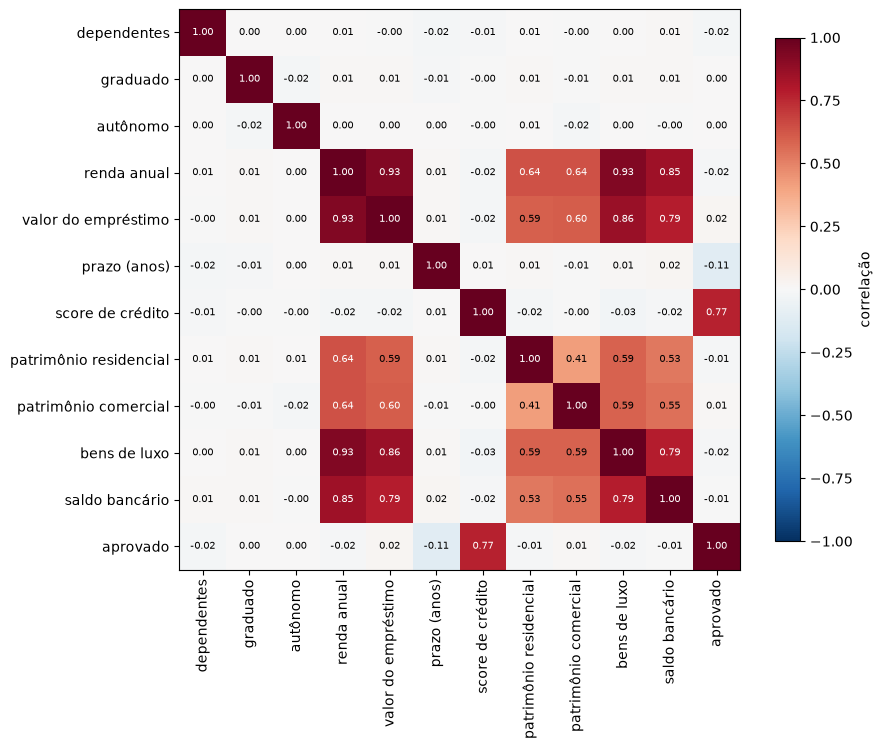

In [5]:
corr = base[config.FEATURES + [config.TARGET]].corr()
rotulos = [config.NOMES[c] for c in corr.columns]

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), rotulos, rotation=90)
ax.set_yticks(range(len(corr)), rotulos)
for i in range(len(corr)):
    for j in range(len(corr)):
        valor = corr.iloc[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(valor) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="correlação")
plt.tight_layout()
plt.show()

Um bloco de atributos financeiros anda junto: a renda anual tem correlação de 0,93 com o valor do empréstimo e com os bens de luxo, e de 0,85 com o saldo bancário. Na prática, eles medem quase a mesma coisa, o tamanho financeiro do cliente. O score de crédito, o prazo e o número de dependentes são independentes de todo o resto.

Na última linha, a correlação com a aprovação: o score tem 0,77, o prazo −0,11, e todos os outros ficam perto de zero.

## 4. Atributos e aprovação

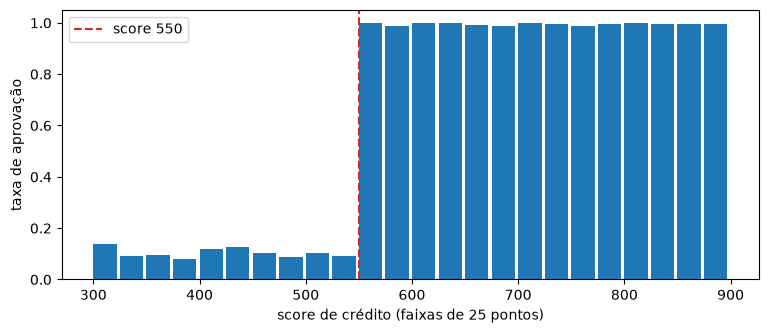

In [6]:
faixa = (base["cibil_score"].clip(upper=899) // 25) * 25
taxa_por_faixa = base.groupby(faixa)[config.TARGET].mean()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(taxa_por_faixa.index, taxa_por_faixa.values, width=22, align="edge", color="tab:blue")
ax.axvline(550, color="tab:red", linestyle="--", label="score 550")
ax.set_xlabel("score de crédito (faixas de 25 pontos)")
ax.set_ylabel("taxa de aprovação")
ax.legend()
plt.show()

A aprovação não sobe aos poucos com o score: ela salta de cerca de 10% para cerca de 99% em 550. É um degrau. Abaixo de 550, ainda há cerca de 10% de aprovados; a tabela abaixo mostra de onde eles vêm.

In [7]:
faixa_score = np.where(base["cibil_score"] >= 550, "score ≥ 550", "score < 550")
pd.crosstab(base["loan_term"], faixa_score, values=base[config.TARGET], aggfunc="mean",
            rownames=["prazo (anos)"], colnames=["taxa de aprovação por faixa de score"]).round(2)

taxa de aprovação por faixa de score,score < 550,score ≥ 550
prazo (anos),,
2,0.48,1.00
4,0.57,0.99
6,0.00,0.99
8,0.00,1.00
10,0.00,0.99
12,0.00,1.00
14,0.00,0.99
16,0.00,1.00
18,0.00,1.00


Com score abaixo de 550, só os prazos de 2 e 4 anos têm aprovados (cerca de metade); com prazo de 6 anos ou mais, ninguém é aprovado. Com score de 550 ou mais, quase todos são aprovados, qualquer que seja o prazo. A regra que gerou os rótulos parece combinar o score e o prazo.

## 5. Até onde vai uma regra simples

In [8]:
limiares = range(500, 601, 5)
acuracia = pd.Series({t: ((base["cibil_score"] >= t).astype(int) == base[config.TARGET]).mean() for t in limiares})
melhor = acuracia.idxmax()
print(f"melhor limiar: {melhor} | acurácia: {acuracia[melhor]:.4f}")

regra = (base["cibil_score"] >= 550).astype(int)
pd.crosstab(regra.map({1: "aprova", 0: "rejeita"}), base[config.TARGET].map({1: "aprovado", 0: "rejeitado"}),
            rownames=["regra score ≥ 550"], colnames=["situação real"])

melhor limiar: 550 | acurácia: 0.9536


situação real,aprovado,rejeitado
regra score ≥ 550,,
aprova,2471,13
rejeita,185,1600


**Resultado.** A regra "aprova se score ≥ 550", de uma linha, acerta 95,4% dos 4.269 pedidos. Ela erra 198: 185 aprovados com score abaixo de 550 (quase todos de prazo curto) e 13 rejeitados com score de 550 ou mais. O limiar de 550 foi escolhido olhando a base inteira; nos modelos, a regra equivalente é aprendida só com o treino (árvore de profundidade 1).

Resumo da etapa:

- **Classes:** 62,2% aprovados; o piso é 62,2% e a divisão treino-teste será estratificada.
- **Origem:** distribuições uniformes e proporções de 50/50 indicam dados provavelmente sintéticos.
- **Redundância:** renda anual, valor do empréstimo, bens de luxo e saldo bancário são fortemente correlacionados.
- **O atributo decisivo:** a aprovação salta em score 550, um degrau; abaixo dele, o prazo curto explica os aprovados.

Para os modelos, isso define a régua: qualquer modelo precisa superar cerca de 95%, o acerto de uma regra de uma linha. Para a rede neural, o degrau é um desafio: uma árvore o representa com uma única pergunta, enquanto a rede trabalha com curvas suaves e precisa de neurônios suficientes para imitá-lo.